# CVID spotting comparison v2 — R5 hoàn tất, đã audit 16/10/2026

**Đã hoàn tất inference, scoring và 6 biểu đồ.** Cohort khóa: **1.754 test frame / 40.063 GT**, 7 course proxies / 276 folder groups; 6 candidate / 10.524 frame-candidate records. Tất cả checkpoint và aggregate đã audit hash/binding. `no_selection`: chưa chọn production winner.

Notebook này giữ outputs Colab gốc, gồm cả lỗi lịch sử và cell khắc phục thành công. Không coi notebook đã chạy sạch mọi cell tuần tự: thứ tự thực thi theo execution_count, có resume/phục hồi. Không cần Run all để xem kết quả.

| Candidate | E2E Hmean (%) | Det P (%) | Det R (%) | Det F1 (%) | Macro-course E2E H (%) |
|---|---:|---:|---:|---:|---:|
| PGNet TotalText joint | 45.60 | 81.12 | 70.44 | 75.40 | 28.01 |
| docTR FAST + PARSeq | 38.13 | 52.28 | 72.65 | 60.81 | 27.66 |
| Tesseract 5 (CPU) | 28.40 | 44.19 | 55.57 | 49.23 | 14.28 |
| EasyOCR | 7.38 | 48.32 | 32.40 | 38.79 | 7.10 |
| Paddle DBv3 + Recv4 | 6.80 | 28.67 | 13.04 | 17.92 | 7.46 |
| PP-OCRv6 Medium | 6.47 | 22.74 | 10.37 | 14.24 | 7.44 |

**Cách đọc:** PGNet pooled cao nhất nhưng macro-course28,01% gần docTR27,66%; docTR cao nhất4/7course. Course20 chiếm42,7%GT. GT gần như word-level (11/40.063 multiword), trong khi Paddle legacy40,99%/PP-OCRv6 50,51% native regions chứa nhiều từ: packaged grouping là một phần của so sánh, không đổi/split theo kết quả test.

**Giới hạn:** nhãn phát hành có chọn lọc; test đã xem trong EDA; không exhaustive visible-text gold/unseen test, causal architecture effect hoặc CPU/GPU speed ranking. Detection và spotting matching độc lập. Crop recognition audit13/10 là endpoint riêng. Zero frame errors không có nghĩa đọc đúng mọi chữ; invalid geometry/empty text vẫn được tính theo protocol.

**Provenance:** evidence cuối `cvid-spotting-t4-261015-v2-r5-evidence (2).zip`, SHA256 `358a51fa96576cbb77820bcbe2177f1b7658556f0e7af1a0355a9276d7b38151`;193-file input bundle SHA256 `40291c603b60eb564a66a182d12ae50cf4b19579954fac5c69c22d87c8ae57df`. Tất cả12 pooled Hmean values trong saved HTML và6 PNG trong notebook khớp evidence. Export cell[17] khớp ZIP cuối.

**Sự cố đã xử lý:** docTR có1checkpoint0byte; phục hồi record gốc từ aggregate đã khóa, giữ recovery journal, không chạy lại OCR. Analyze returncode0. Render venv lỗi kế thừa inline backend; cell Agg độc lập returncode0 đã tạo6plots và full tables. Failure ledger lịch sử được giữ, không giả 0 lỗi notebook.

**Trình tự xem:** bảng/plots ở cell render Agg thành công; viewer có đầy đủ9GT và native outputs6candidate cho frame mặc định; các fulltext/frame-score exports ở evidence. Phần slide-transition → keyframe tiếp theo phải khóa riêng media/timebase/GT/cohort/protocol; chưa bắt đầu chạy benchmark.


R5: preflight và warm-up trước test dùng chung inference + mở ảnh + geometry checks, rồi mới so toàn bộ runtime/native hashes. Sau ALL6 preflight có ALL6 train replay trong process mới; chưa đọc ảnh test. Mismatch lưu binding diff và cả expected/actual runtime dưới diagnostics và hiển thị trong notebook. Giữ r4 evidence/EasyOCR riêng; source/bundle identity đã đổi nên không chép records r4 sang r5. R5 cần preflight/replay mới và test mới. R5 T4 preflight/replay/inference đã được audit; xem tổng kết đầu notebook.


In [1]:
from pathlib import Path
import sys, os, json, subprocess, hashlib, zipfile, shutil, time, uuid
from IPython.display import display, HTML
from html import escape
from google.colab import drive, files
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/OCR')  # explicit persistent destination
RUN_ID = 'cvid-spotting-t4-261015-v2-r5'
CACHE_ID = 'cvid-spotting-t4-261015-v2-r2'  # reuse exact wheels/seals, never old run receipts
BUNDLE_ZIP = DRIVE_ROOT / 'iiit-cvid-spotting-colab-t4-inputs-v2.zip'
SOURCE_ZIP = None  # optional existing source ZIP path on Drive; otherwise pinned HF download
WORK = Path('/content/cvid-spotting-t4')
ROOT = WORK / 'runner'
OUT = DRIVE_ROOT / RUN_ID
# Keep exact wheels and package seals across Colab VM loss, outside evidence ZIP.
os.environ['SPOTTING_CACHE_ROOT'] = str(DRIVE_ROOT / (CACHE_ID + '-runtime-cache'))
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,uuid,memory.total,driver_version',
                      '--format=csv,noheader'], check=True, text=True, capture_output=True)
print(gpu.stdout)
if 'T4' not in gpu.stdout:
    raise RuntimeError('This profile requires a T4. Select T4 and restart; do not reuse another GPU profile.')

print('OUT:',OUT,'Disk free GB:',round(shutil.disk_usage('/content').free/1e9,2))


Mounted at /content/drive
Tesla T4, GPU-e9b00210-c5b2-1c30-6311-c5625bf86051, 15360 MiB, 580.82.07

OUT: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5 Disk free GB: 207.57


## 1. Upload / verify comparison bundle hiện hành
Nếu ZIP chưa có trên Drive, cell hỏi upload từ máy. SHA và mọi member được kiểm trước khi gọi runner. Không upload qualification ZIP vào bước này. Tên ZIP giữ cố định; tải lại bản khớp notebook hiện hành.


In [2]:
EXPECTED_BUNDLE_SHA256 = '40291c603b60eb564a66a182d12ae50cf4b19579954fac5c69c22d87c8ae57df'
def file_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()
if not BUNDLE_ZIP.is_file():
    uploaded = files.upload()
    assert len(uploaded)==1, 'Upload đúng một comparison bundle.'
    upload_name, upload_bytes = next(iter(uploaded.items()))
    assert hashlib.sha256(upload_bytes).hexdigest()==EXPECTED_BUNDLE_SHA256, 'ZIP không khớp notebook.'
    BUNDLE_ZIP.parent.mkdir(parents=True,exist_ok=True)
    BUNDLE_ZIP.write_bytes(upload_bytes)
if file_sha(BUNDLE_ZIP) != EXPECTED_BUNDLE_SHA256:
    raise ValueError('Bundle hash differs from this notebook. Use the matching notebook/ZIP pair.')
from pathlib import PurePosixPath
with zipfile.ZipFile(BUNDLE_ZIP) as archive:
    names = archive.namelist()
    if len(names) != len(set(names)):
        raise ValueError('Duplicate ZIP members')
    for name in names:
        if PurePosixPath(name).is_absolute() or '..' in PurePosixPath(name).parts or '\\' in name or ':' in name:
            raise ValueError('Unsafe ZIP member')
    manifest = json.loads(archive.read('bundle-manifest.json'))
    entries = manifest['files']
    if len(entries) != len({e['path'] for e in entries}) or set(names) != {e['path'] for e in entries} | {'bundle-manifest.json'}:
        raise ValueError('Bundle membership changed')
    for entry in entries:
        value = archive.read(entry['path'])
        if len(value) != entry['bytes'] or hashlib.sha256(value).hexdigest() != entry['sha256']:
            raise ValueError('Bundle file changed: ' + entry['path'])
    # Use a fresh source directory to avoid stale modules outside the manifest.
    if ROOT.exists():
        shutil.rmtree(ROOT)
    archive.extractall(ROOT)
sys.path.insert(0, str(ROOT))
print('Verified bundle files:', len(entries))

from experiments.scripts.spotting_colab_candidates import load_registry
from experiments.scripts.spotting_colab_review import table, status_rows, require_preflights, require_train_replays
from experiments.scripts.spotting_colab_state import read
REGISTRY_PATH = ROOT/'experiments/registry/datasets/iiit-cvid-spotting-colab-t4-candidates-261015-v2.json'
registry = load_registry(REGISTRY_PATH)
assert len(registry['candidates'])==6 and all(not c.get('conditional',False) for c in registry['candidates'])
table([dict(candidate_id=c['candidate_id'],environment=c['environment'],locked=c['locked'],configuration_sha256=c['configuration_sha256']) for c in registry['candidates']], 'Six locked candidates')
table([read(ROOT/'experiments/registry/datasets/iiit-cvid-pgnet-t4-qualification-audit-261015.json')], 'PGNet qualification audited — not comparison completion')
for name in ['protocol','gt-policy']:
    value = read(ROOT/('experiments/registry/datasets/iiit-cvid-spotting-test-261014-'+name+'.json'))
    display(HTML('<details><summary>Frozen '+escape(name)+'</summary><pre>'+escape(json.dumps(value,ensure_ascii=False,indent=2))+'</pre></details>'))

for candidate in registry["candidates"]:
    display(HTML("<details><summary>Locked candidate: "+escape(candidate["candidate_id"])+"</summary><pre>"+escape(json.dumps(candidate,ensure_ascii=False,indent=2))+"</pre></details>"))


Verified bundle files: 193


candidate_id,environment,locked,configuration_sha256
easyocr_craft_english_g2_t4,torch,True,cad3109ef76ee2dd80e406a163caf64f641ba61cbe1c5ad68a10fe6fc359cdfd
paddle_db_v3_rec_v4_t4,paddle_legacy,True,94890f9584cddcb811661459bc94fdfb40fdbec136412b40db4601c1bf99841c
tesseract5_best_eng_cpu,cpu,True,40eaf6d19a7d3bf0833798c5d5962979445c002eddb60398d07033cb8698bb6d
doctr_fast_base_parseq_t4,torch,True,61f6c539a8882292039e65320680816fb93d80d051aba32e64984de0d4ba47f8
paddle_ppocrv6_medium_t4,paddle_modern,True,5155454b427dab7818424215dea9223841f9db5b760a2d947a7fbf7f48df5aa6
pgnet_totaltext_joint_t4,paddle_legacy,True,2f237b8179a602f66fee37b14997942af0fe95228991bf6f30a5013729e5f3e5


schema,status,candidate_id,device,train_frames,regions,invalid_native_predictions,preflight_sha256,evidence_zip_sha256,no_test_inference,comparison_preflight_reuse_allowed
cvid_pgnet_t4_qualification_audit_v1,audited_passed,pgnet_totaltext_joint_t4,Tesla T4,9,199,1,262b8a920620e3cbdb562c2db510790dd4ea8b3a7ac3bb50b4efa8e809653c13,55663a24c6156933015d42c642f827d6627f4875daca1f16af88b0c598613d2e,True,False


## 2. Isolated orchestrator, source và model preparation
Không cài package vào kernel Colab. Bootstrap tránh host ensurepip; Python3.11 orchestrator/scorer và model venvs có seals riêng. Giữ đường dẫn driver sau CUDA/cuDNN wheels. Runtime mới có thể tải source và packages lớn; chưa có thời lượng chạy đo cho cả6 pipelines.


In [3]:
from experiments.scripts.spotting_colab_environments import prepare_environment
try:
    PYTHON, orchestrator_seal = prepare_environment(dict(candidate_id='orchestrator',environment='scoring',packages=['pandas==2.2.3','matplotlib==3.10.1','huggingface_hub==0.30.2']),WORK)
except ValueError as reconstruction_error:
    if "offline reconstruction differs" in str(reconstruction_error):
        from experiments.scripts.spotting_colab_environments import environment_snapshot
        from experiments.scripts.spotting_colab_artifacts import digest
        def snapshot_difference(expected, actual):
            result = dict(python_changed=expected['python'] != actual['python'],
                          interpreter_changed=expected['executable_sha256'] != actual['executable_sha256'],
                          packages=[])
            original, rebuilt = expected['packages'], actual['packages']
            for name in sorted(set(original) | set(rebuilt)):
                before, after = original.get(name), rebuilt.get(name)
                if before == after:
                    continue
                row = dict(package=name, expected_version=(before or {}).get('version'),
                           actual_version=(after or {}).get('version'))
                files_before, files_after = (before or {}).get('files', {}), (after or {}).get('files', {})
                row['missing_files'] = sorted(set(files_before) - set(files_after))
                row['added_files'] = sorted(set(files_after) - set(files_before))
                row['changed_files'] = [dict(path=p, expected=files_before[p], actual=files_after[p])
                                        for p in sorted(set(files_before) & set(files_after)) if files_before[p] != files_after[p]]
                result['packages'].append(row)
            return result


        cache_root = Path(os.environ.get('SPOTTING_CACHE_ROOT',
                          '/content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r2-runtime-cache'))
        seal_path = cache_root / 'environments/orchestrator/environment-seal.json'
        python = Path('/content/cvid-spotting-t4/environments/orchestrator/venv/bin/python')
        assert seal_path.is_file(), 'Mount Drive and locate the r2 orchestrator cache seal first.'
        assert python.is_file(), 'Actual rebuilt environment is no longer present; use the updated notebook to capture the next reconstruction failure.'
        cached = json.loads(seal_path.read_text())
        actual = environment_snapshot(python)
        report = snapshot_difference(cached['installed'], actual)
        report.update(expected_digest=cached['installed_digest'], actual_digest=digest(actual),
                      cached_snapshot_self_consistent=digest(cached['installed']) == cached['installed_digest'])
        out = OUT
        out.mkdir(parents=True, exist_ok=True)
        report_path = out / 'orchestrator-reconstruction-diff.json'
        report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
        print(json.dumps(report, ensure_ascii=False, indent=2))
        assert json.loads(report_path.read_text(encoding='utf-8')) == report
        print('Saved:', report_path)
        files.download(str(report_path))  # Keep a local copy before disconnecting runtime.
    raise
print('Orchestrator:',PYTHON,'installed_digest:',orchestrator_seal['installed_digest'])
print('Orchestrator check finished. No dataset download, model install or inference has run in this cell.')


Orchestrator: /content/cvid-spotting-t4/environments/orchestrator/venv/bin/python installed_digest: 17b722c54dfe8604e2b17284b194e2fcd359e4c1a4576e6712a60cb7b2d309ef
Orchestrator check finished. No dataset download, model install or inference has run in this cell.


### Tiếp tục acquisition/model preparation sau khi orchestrator đạt
Nếu đang thu diff cache, dừng trước cell này. Ba code cells đầu chỉ mount/verify và kiểm orchestrator. Nếu mismatch, JSON được lưu lên Drive và gọi tải về máy trước khi báo lỗi; chưa có model inference.


In [6]:
ARCHIVE = Path(SOURCE_ZIP) if SOURCE_ZIP else WORK / 'IIIT-CVid.zip'
if not ARCHIVE.exists():
    download_script = """from huggingface_hub import hf_hub_download, list_repo_files
import shutil, sys
repo = 'staghado/IIIT-CVid'
revision = '8159222f11460bff70bec7990ade19c468755fe4'
choices = [p for p in list_repo_files(repo, repo_type='dataset', revision=revision) if p.endswith('.zip')]
assert len(choices) == 1, choices
cached = hf_hub_download(repo, choices[0], repo_type='dataset', revision=revision)
shutil.copyfile(cached, sys.argv[1])
"""
    subprocess.run([str(PYTHON), '-c', download_script, str(ARCHIVE)], check=True)
if file_sha(ARCHIVE) != 'b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489':
    raise ValueError('Source archive differs from frozen CVID release')
BASE = [str(PYTHON), '-m', 'experiments.scripts.run_spotting_colab',
        '--bundle-root', str(ROOT), '--work-root', str(WORK), '--output-root', str(OUT),
        '--candidate-registry', str(ROOT / 'experiments/registry/datasets/iiit-cvid-spotting-colab-t4-candidates-261015-v2.json'), '--source-zip', str(ARCHIVE)]

def tail_text(path):
    with Path(path).open('rb') as handle:
        handle.seek(max(0,Path(path).stat().st_size-12000))
        return handle.read().decode('utf-8',errors='replace')
def cli(command,candidate=None,check=True):
    import signal
    args = BASE+[command]+(['--candidate',candidate] if candidate else [])
    log = OUT/'orchestrator-logs'/(command+'-'+uuid.uuid4().hex+'.log')
    log.parent.mkdir(exist_ok=True)
    panel = display(HTML('<b>'+escape(command)+' RUNNING</b>'),display_id=True)
    with log.open('w') as stream:
        process = subprocess.Popen(args,cwd=ROOT,stdout=stream,stderr=subprocess.STDOUT,start_new_session=True)
        try:
            while process.poll() is None:
                text = tail_text(log)
                workers = list(OUT.glob('*/logs/*.log'))
                if workers:
                    latest = max(workers,key=lambda p:p.stat().st_mtime)
                    text += '\nLATEST WORKER: '+str(latest)+'\n'+tail_text(latest)
                panel.update(HTML('<b>'+escape(command)+' RUNNING</b><pre>'+escape(text[-18000:])+'</pre>'))
                time.sleep(3)
            code = process.wait()
        except KeyboardInterrupt:
            os.killpg(process.pid,signal.SIGTERM)
            try: process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid,signal.SIGKILL)
                process.wait()
            raise
    panel.update(HTML('<b>'+escape(command)+' returncode='+str(code)+'</b><pre>'+escape(tail_text(log))+'</pre>'))
    table(status_rows(OUT,registry),'Candidate status after '+command)
    print('Full phase log:',log)
    if code!=0:
        phase = 'infer' if command=='run' else command
        for failed in status_rows(OUT,registry):
            if candidate and failed['candidate_id']!=candidate:
                continue
            if failed['latest_failure']:
                paths = list((OUT/failed['candidate_id']/'logs').glob(phase+'-*.log'))
                if paths:
                    path = max(paths,key=lambda p:p.stat().st_mtime)
                    display(HTML('<b>FAILED WORKER: '+escape(str(path))+'</b><pre>'+escape(tail_text(path))+'</pre>'))
                diagnostics = sorted((OUT/failed['candidate_id']/'diagnostics').glob('runtime-mismatch-'+phase+'-*.json'),key=lambda p:p.stat().st_mtime)
                if diagnostics:
                    diagnostic = read(diagnostics[-1])
                    print('Full runtime snapshots:',diagnostics[-1])
                    table(diagnostic['binding_diff'],'Binding differences')
                    table(diagnostic['runtime_diff'],'Runtime differences (no fields omitted)')
    if check and code!=0:
        raise RuntimeError('Phase failed; inspect logs/failures and export evidence. Do not change config.')
    return code
cli('prepare')


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,192,pending,,,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,0,pending,,,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/prepare-52b9b3994a9047dba2b29cb188dcb2d7.log


0

## 3. Data review và ALL6 preflight
Giữ selected IDs/GT:1.754/40.063,1 whole-frame geometry HOLD và97 metadata-only repairs. Models chỉ nhận full PNG. Preflight mới dùng9 train inputs, không test scores; qualification PGNet không được nhập làm gate. Mọi required gate phải PASS trước ANY test inference.


In [7]:
data = read(OUT/'prepared-data.json')
assert len(data['frames'])==1754 and sum(r['object_count'] for r in data['frames'])==40063
table([dict(course=course,frames=sum(r['course']==course for r in data['frames']),gt=sum(r['object_count'] for r in data['frames'] if r['course']==course)) for course in sorted({r['course'] for r in data['frames']})], 'Frozen cohort by course')
table([dict(frame_id=r['frame_id'],course=r['course'],source_group=r['source_group'],gt=r['object_count'],decision=r['decision']) for r in data['frames']], 'ALL 1754 selected frame IDs')
table(data['train_preflight'],'Train preflight inputs')
preflight_order = sorted(registry['candidates'],key=lambda c:c['adapter']!='doctr')
for candidate in preflight_order:
    preflight_code = cli('preflight',candidate=candidate['candidate_id'],check=False)
    assert preflight_code == 0, 'Current candidate preflight failed; inspect the displayed worker traceback and export before test.'
require_preflights(OUT,registry)
print('PASS ALL6 preflight. Now replay train in fresh isolated processes; no test pixels.')
for candidate in preflight_order:
    replay_code = cli('verify',candidate=candidate['candidate_id'],check=False)
    assert replay_code == 0, 'Train replay binding failed; inspect diagnostics and export evidence before test.'
require_train_replays(OUT,registry)
print('PASS ALL6 preflight + separate-process train replay. Test is admitted.')


course,frames,gt
10,224,2976
14,245,4910
18,282,5671
20,368,17097
24,243,5906
3,140,1261
7,252,2242


frame_id,course,source_group,gt,decision
Frames/test/10/1/00_03_40_00001.png,10,10/1,9,KEEP
Frames/test/10/1/00_13_09_00002.png,10,10/1,15,KEEP
Frames/test/10/1/00_15_26_00003.png,10,10/1,10,KEEP
Frames/test/10/1/00_18_20_00004.png,10,10/1,12,KEEP
Frames/test/10/1/00_19_47_00005.png,10,10/1,15,KEEP
Frames/test/10/1/00_27_54_00006.png,10,10/1,24,KEEP
Frames/test/10/1/00_30_08_00007.png,10,10/1,19,KEEP
Frames/test/10/1/00_35_10_00008.png,10,10/1,7,KEEP
Frames/test/10/1/00_49_17_00009.png,10,10/1,14,KEEP
Frames/test/10/10/00_01_22_00001.png,10,10/10,11,KEEP


frame_id,image_sha256
Frames/train/1/1/00_00_50_00001.png,16c464ae42e0b4ac274910194a58da6789bbe2041e8c1f52c04ddb3edc27a4b8
Frames/train/12/1/00_00_33_00001.png,2caa302ce5701a8425bf31baa120462dd7616933d27582fa042ffea729dda9c3
Frames/train/15/1/00_03_25_00001.png,a5e7460868f9663938314e8d126e17f570eac99f6ecf2c70b1bc9c4dcafa56ee
Frames/train/16/1/00_09_38_00001.png,bd409ec06bd42709c9a82b56997196444dbdad5b276a1b78f0e22d31f3671577
Frames/train/17/10/00_08_10_00001.png,cf709d5ad318b48b3f12e823525aeceb6264d3ed9e26f464327687f9e6157f9d
Frames/train/21/1/00_02_38_00001.png,a2507f99ee4ca07e6b9ebf08093990acb80cd7bcb4c98b68a13515720e60afe1
Frames/train/22/1/00_01_20_00001.png,1331f8f82f610b1a1f4e700c8b53dc7759434e6031bb3698006cfdad53e88df6
Frames/train/4/1/00_09_55_00001.png,ee4627870ad4ce956e667c21676d61b9118ab0e00e73d67721c64ea098f4c93e
Frames/train/5/1/00_01_07_00001.png,4d6a533e74dc952d04cd649d852115a1d653f71b06e57213d2da6f5fbe3719c3


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,192,pending,,,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,0,pending,,,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/preflight-739e6fb522864897b93668315b6b7235.log


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,192,pending,,,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,0,pending,,,


... (17 outputs left out)

candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,192,pending,,,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,0,pending,,,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/verify-1797d0034f704ed99c33399d7ae56741.log


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,192,pending,,,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,0,pending,,,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/verify-2e6a365c58fe48a79958668db6001b40.log
PASS ALL6 preflight + separate-process train replay. Test is admitted.


## 4. Full cohort — immutable checkpoints
Chỉ chạy khi ALL6 preflight và ALL6 separate-process train replay PASS. Mỗi candidate commit đủ1.754 frame; frame error giữ GT/FN và zero predictions. Không chạy lỗi bằng config khác, bỏ candidate hoặc bỏ frame. Cùng RUN_ID/bundle/runtime để resume; identity thay đổi phải dùng run mới. Worker giữ records đã commit. Không nhập CPU results cũ.


In [10]:
from google.colab import files
from pathlib import Path
import subprocess, sys

uploaded = files.upload()  # chọn recover-cvid-r5-doctr-checkpoint.py
name = "recover-cvid-r5-doctr-checkpoint.py"
script = Path("/content") / name
script.write_bytes(uploaded[name])
subprocess.run([sys.executable, str(script)], check=True)

Saving recover-cvid-r5-doctr-checkpoint.py to recover-cvid-r5-doctr-checkpoint.py


CompletedProcess(args=['/usr/bin/python3', '/content/recover-cvid-r5-doctr-checkpoint.py'], returncode=0)

Lỗi lịch sử giữ nguyên để truy vết. Lần resume docTR đọc1checkpoint rỗng; record đã phục hồi từ sealed aggregate và scorer kiểm toàn bộ thành công. Không cần chạy lại cell inference này.


In [8]:
require_train_replays(OUT,registry)
cli('run')
rows = status_rows(OUT,registry)
assert all(r['complete']=='complete' and r['committed_frames']==1754 for r in rows if r['required']), 'Incomplete six-candidate cohort; export evidence, no scores yet.'
print('Complete coverage: 10524 frame-candidate records, including recorded failures.')


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,ValueError: isolated process failed; inspect /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/doctr_fast_base_parseq_t4/logs/infer-d9a1e9e0211144509b202f7f6dafc9fa.log
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/run-fc0e109053284d23bbf6111508a7bef1.log


RuntimeError: Phase failed; inspect logs/failures and export evidence. Do not change config.

## 5. Scoring, toàn bộ tables và plots
Pooled E2E Hmean chính; detection P/R/F1, TP/FP/FN, failure/invalid/empty, macro-course, course/folder tables. Fixed sensitivities: IoU>0.75, case-sensitive,3-frame influence subset (1.751/40.023), dùng cùng predictions. Exploratory paired bootstrap course/folder, không winner/generalization claim. Primary frame table đủ IDs; full transcription qua viewer và gz exports.


Lỗi lịch sử giữ nguyên để truy vết. Analyze đã thành công; chỉ render bị inline-backend inheritance. Cell render_env[MPLBACKEND]=Agg phía sau đã chạy thành công, full tables và6plots khớp receipt. Không cần chạy lại analyze.


In [11]:
cli('analyze')
subprocess.run([str(PYTHON),'-m','pip','check'],check=True)
subprocess.run([str(PYTHON),'-c','from experiments.scripts.spotting_colab_notebook import render_figures; import sys; render_figures(sys.argv[1])',str(OUT)],cwd=ROOT,check=True)
from experiments.scripts.spotting_colab_review import display_full_results
display_full_results(OUT)


candidate_id,required,prepared,preflight,train_replay,device,train_frames,committed_frames,complete,successful_frames,failed_frames,latest_failure
easyocr_craft_english_g2_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
paddle_db_v3_rec_v4_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
tesseract5_best_eng_cpu,True,True,passed,passed,cpu,9,1754,complete,1754,0,
doctr_fast_base_parseq_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,ValueError: isolated process failed; inspect /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/doctr_fast_base_parseq_t4/logs/infer-d9a1e9e0211144509b202f7f6dafc9fa.log
paddle_ppocrv6_medium_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,
pgnet_totaltext_joint_t4,True,True,passed,passed,Tesla T4,9,1754,complete,1754,0,


Full phase log: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/orchestrator-logs/analyze-f0017bdb9e5d4be0ae1d6f79baf582b2.log


CalledProcessError: Command '['/content/cvid-spotting-t4/environments/orchestrator/venv/bin/python', '-c', 'from experiments.scripts.spotting_colab_notebook import render_figures; import sys; render_figures(sys.argv[1])', '/content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5']' returned non-zero exit status 1.

## 6. Any-frame review: GT và sáu native predictions
Dropdown chứa đủ1.754 frame. Chọn rồi chạy viewer bên dưới; nếu không có widgets thì sửa FRAME_ID. Mặc định frame đầu cohort, không chọn theo điểm. GT xanh/prediction xanh dương không biểu thị TP/FP.



Render returncode: 0
COMPLETE ANALYSIS: 1754 frames; 40063 GT; 6 candidates
Selection: no_selection — EDA-exposed selective released labels; seven course proxies; exploratory unadjusted CIs; no production winner or CPU/GPU speed equivalence


candidate_id,variant,metric,selected_frames,failed_frames,tp,fp,fn,precision,recall,hmean
easyocr_craft_english_g2_t4,primary,spotting,1754,0,2468,24396,37595,0.09187016081000596,0.06160297531388064,0.0737519984460681
easyocr_craft_english_g2_t4,primary,detection,1754,0,12981,13883,27082,0.48321173317450866,0.32401467688390784,0.38791519117844814
easyocr_craft_english_g2_t4,strict_iou,spotting,1754,0,1012,25852,39051,0.03767123287671233,0.025260215161121233,0.030241905359570876
easyocr_craft_english_g2_t4,strict_iou,detection,1754,0,4534,22330,35529,0.168776057176891,0.11317175448668347,0.13549090800424343
easyocr_craft_english_g2_t4,case_sensitive,spotting,1754,0,1003,25861,39060,0.03733621203097082,0.025035568978858298,0.029972955608349394
easyocr_craft_english_g2_t4,case_sensitive,detection,1754,0,12981,13883,27082,0.48321173317450866,0.32401467688390784,0.38791519117844814
easyocr_craft_english_g2_t4,observed_flag_frame_influence,spotting,1751,0,2467,24368,37556,0.09193217812558226,0.06163955725457862,0.07379819916838673
easyocr_craft_english_g2_t4,observed_flag_frame_influence,detection,1751,0,12958,13877,27065,0.4828768399478293,0.3237638357944182,0.38762750904902926
paddle_db_v3_rec_v4_t4,primary,spotting,1754,0,1983,16235,38080,0.10884839170051597,0.04949704215860021,0.06804962166057549
paddle_db_v3_rec_v4_t4,primary,detection,1754,0,5223,12995,34840,0.28669447798880227,0.13036966777325712,0.17923508519071396


candidate_id,variant,metric,courses,mean_course_hmean
easyocr_craft_english_g2_t4,primary,spotting,7,0.07102356140252734
easyocr_craft_english_g2_t4,primary,detection,7,0.43824862337777254
easyocr_craft_english_g2_t4,strict_iou,spotting,7,0.02872359928484201
easyocr_craft_english_g2_t4,strict_iou,detection,7,0.15551083033943017
easyocr_craft_english_g2_t4,case_sensitive,spotting,7,0.025643013033625008
easyocr_craft_english_g2_t4,case_sensitive,detection,7,0.43824862337777254
easyocr_craft_english_g2_t4,observed_flag_frame_influence,spotting,7,0.0711097911654211
easyocr_craft_english_g2_t4,observed_flag_frame_influence,detection,7,0.4380068214157177
paddle_db_v3_rec_v4_t4,primary,spotting,7,0.07455884892669504
paddle_db_v3_rec_v4_t4,primary,detection,7,0.2003230054293801


candidate_id,variant,metric,group_type,group,frames,tp,fp,fn,precision,recall,hmean
easyocr_craft_english_g2_t4,primary,spotting,course,10,224,237,1746,2739,0.11951588502269289,0.07963709677419355,0.0955837870538415
easyocr_craft_english_g2_t4,primary,detection,course,10,224,1413,570,1563,0.7125567322239031,0.4747983870967742,0.5698729582577132
easyocr_craft_english_g2_t4,primary,spotting,course,14,245,146,3082,4764,0.045229244114002476,0.029735234215885947,0.03588105185549275
easyocr_craft_english_g2_t4,primary,detection,course,14,245,2133,1095,2777,0.6607806691449815,0.4344195519348269,0.5242074219710002
easyocr_craft_english_g2_t4,primary,spotting,course,18,282,326,5128,5345,0.05977264393105977,0.05748545230118145,0.05860674157303371
easyocr_craft_english_g2_t4,primary,detection,course,18,282,3061,2393,2610,0.5612394572790612,0.5397637101040381,0.5502921348314607
easyocr_craft_english_g2_t4,primary,spotting,course,20,368,704,3800,16393,0.15630550621669628,0.0411768146458443,0.06518216749224573
easyocr_craft_english_g2_t4,primary,detection,course,20,368,1229,3275,15868,0.2728685612788632,0.07188395624963444,0.1137910281931392
easyocr_craft_english_g2_t4,primary,spotting,course,24,243,833,7213,5073,0.10352970420084515,0.14104300711141213,0.11940940366972477
easyocr_craft_english_g2_t4,primary,detection,course,24,243,3765,4281,2141,0.4679343773303505,0.6374873010497799,0.5397075688073395


candidate_id,anchor,variant,group_key,delta,low,high,draws,seed
easyocr_craft_english_g2_t4,paddle_db_v3_rec_v4_t4,primary,course,0.0057023767854926105,-0.03424392481105942,0.02294629573857132,2000,20261014
easyocr_craft_english_g2_t4,paddle_db_v3_rec_v4_t4,primary,source_group,0.0057023767854926105,-0.0032172637426331474,0.014769124415794671,2000,20261014
tesseract5_best_eng_cpu,paddle_db_v3_rec_v4_t4,primary,course,0.21597143003992425,-0.04039875656511949,0.4264680689499345,2000,20261014
tesseract5_best_eng_cpu,paddle_db_v3_rec_v4_t4,primary,source_group,0.21597143003992425,0.17895098468501003,0.2547181560330191,2000,20261014
doctr_fast_base_parseq_t4,paddle_db_v3_rec_v4_t4,primary,course,0.3132270807660157,0.11173289789410813,0.5082948322239745,2000,20261014
doctr_fast_base_parseq_t4,paddle_db_v3_rec_v4_t4,primary,source_group,0.3132270807660157,0.2794619325252802,0.3489147894568704,2000,20261014
paddle_ppocrv6_medium_t4,paddle_db_v3_rec_v4_t4,primary,course,-0.0033178231931556695,-0.01977108018151208,0.009948875318495976,2000,20261014
paddle_ppocrv6_medium_t4,paddle_db_v3_rec_v4_t4,primary,source_group,-0.0033178231931556695,-0.008467752470317745,0.001906319353294647,2000,20261014
pgnet_totaltext_joint_t4,paddle_db_v3_rec_v4_t4,primary,course,0.3879144655561838,0.09917781755991992,0.627920832379476,2000,20261014
pgnet_totaltext_joint_t4,paddle_db_v3_rec_v4_t4,primary,source_group,0.3879144655561838,0.3412550793485605,0.4356128279215733,2000,20261014


Zero rows; no entries omitted.


... (4 outputs left out)

candidate_id,frames
easyocr_craft_english_g2_t4,1754
paddle_db_v3_rec_v4_t4,1754
tesseract5_best_eng_cpu,1754
doctr_fast_base_parseq_t4,1754
paddle_ppocrv6_medium_t4,1754
pgnet_totaltext_joint_t4,1754


Full texts/polygons: /content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5/all-prediction-text.csv.gz — inspect ANY frame in the following viewer or download this file; no text shortened.


file,path,rows,sha256
all-prediction-text.csv.gz,all-prediction-text.csv.gz,10524,37b49a49f776fcbd1509c1bbe039a2e9cc070d4dd5981b2e7e5952f65057a422
bootstrap.csv,bootstrap.csv,40,84e16d671271d6c26e453b0ef3b1514a3ae3cc4a51bb04be139cf0cdd464d951
failure-ledger.csv,failure-ledger.csv,0,33d742c36a8f7fc700a60d6e43633a613db7c0ae061cb4d553473f7e304670f7
frame-scores.csv.gz,frame-scores.csv.gz,42078,f03f336e7036aa2ca51e4273e72a312bffe1b6e2dc388cdb541e4c7e3b5f734f
group-metrics.csv,group-metrics.csv,13584,59699751f923eea85f1f438f9bade9a19bfa34f9740b83fe3b8b25e2d335442d
macro-course-means.csv,macro-course-means.csv,48,89727f952da02e5431923d2ec459ef7b116cbd0076db540a665e2f594568abd7
metrics.csv,metrics.csv,48,8e11ba8c2694b6d1c62e9aba52506d527a263d68e6d4ed63fd1bb14fa68fa477


figures/01-primary-hmean.png


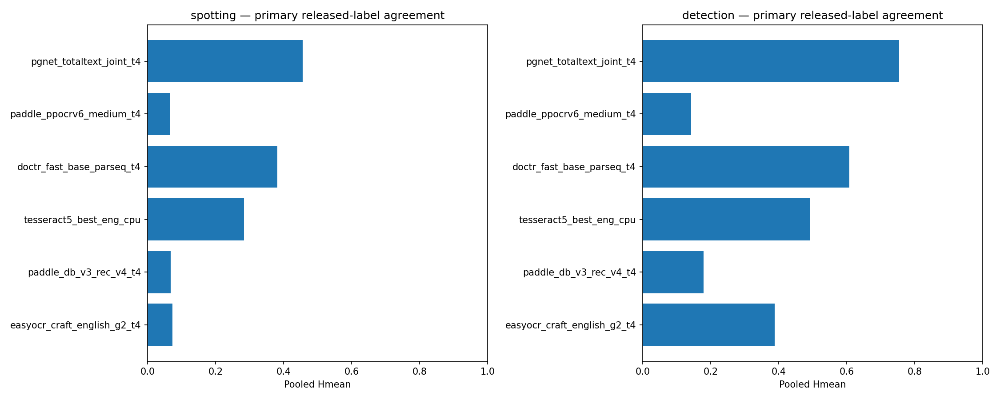

figures/02-detection-prf.png


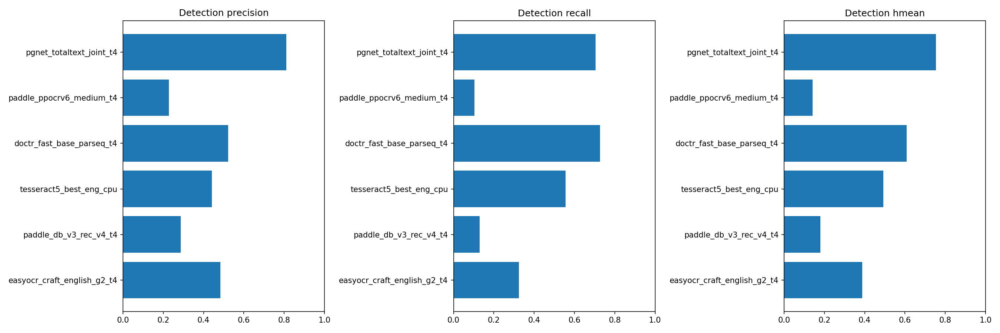

figures/03-fixed-sensitivity.png


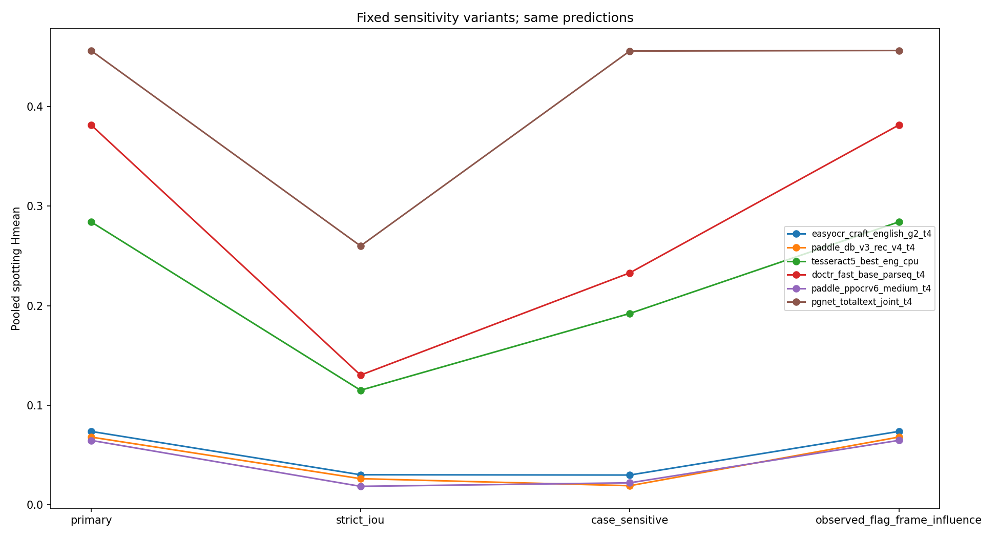

figures/04-course-breakdown.png


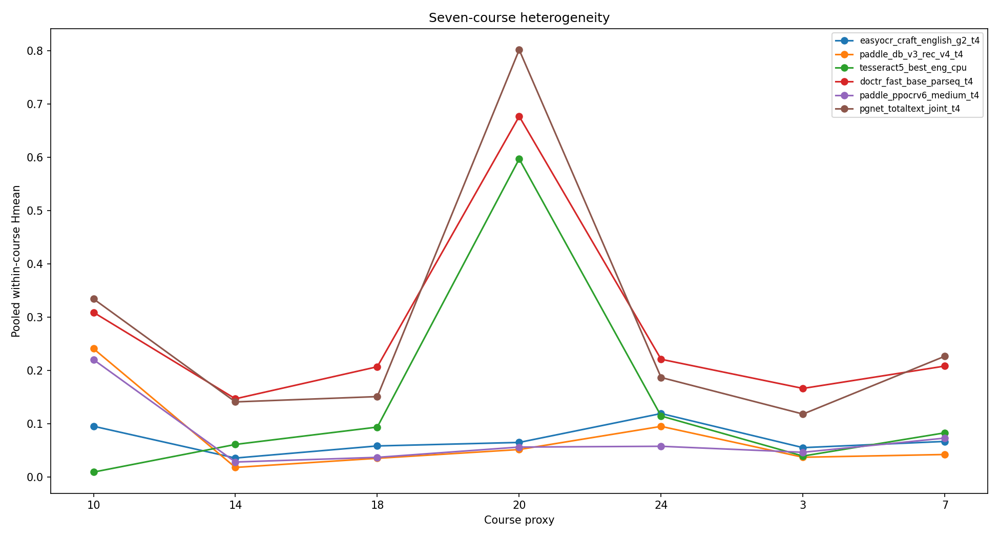

figures/05-failure-coverage.png


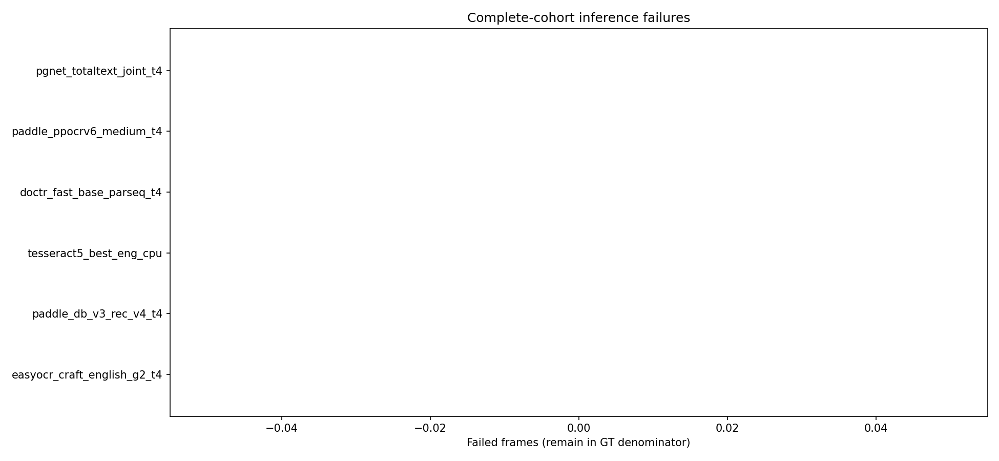

figures/06-paired-uncertainty.png


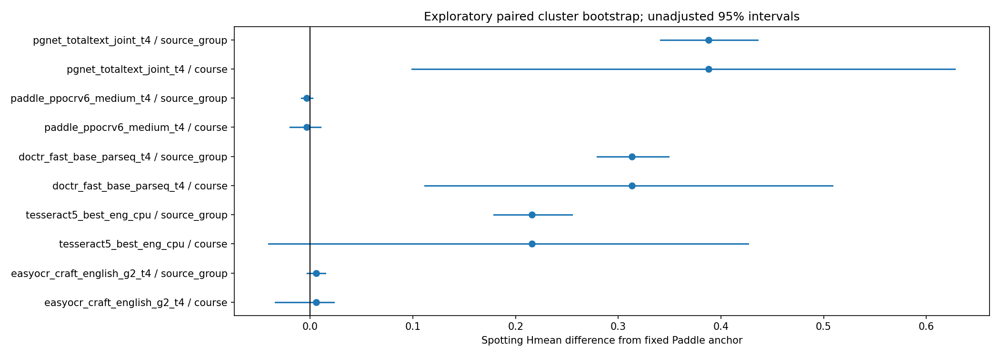

In [13]:
import os, subprocess

render_env = os.environ.copy()
render_env["MPLBACKEND"] = "Agg"

result = subprocess.run(
    [
        str(PYTHON), "-c",
        "from experiments.scripts.spotting_colab_notebook import render_figures; "
        "import sys; render_figures(sys.argv[1])",
        str(OUT),
    ],
    cwd=ROOT,
    env=render_env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)
print(result.stdout)
print("Render returncode:", result.returncode)
assert result.returncode == 0, "Gửi traceback mới nếu render còn lỗi."

from experiments.scripts.spotting_colab_review import display_full_results
display_full_results(OUT)

In [14]:
FRAME_ID = data['frames'][0]['frame_id']
try:
    import ipywidgets as widgets
    FRAME_SELECTOR = widgets.Dropdown(options=[r['frame_id'] for r in data['frames']],value=FRAME_ID,description='Frame ID:',layout={'width':'95%'})
    display(FRAME_SELECTOR)
except ImportError:
    FRAME_SELECTOR = None
    print('Edit FRAME_ID:',FRAME_ID)


Dropdown(description='Frame ID:', layout=Layout(width='95%'), options=('Frames/test/10/1/00_03_40_00001.png', …

Frames/test/10/1/00_03_40_00001.png — 9 released GT; GREEN=GT, BLUE=prediction. Colors do not denote TP/FP matches.


object_id,text,bbox
Frames/test/10/1/00_03_40_00001.png#object-0000,computer,"[62, 31, 143, 52]"
Frames/test/10/1/00_03_40_00001.png#object-0001,madras,"[245, 224, 281, 234]"
Frames/test/10/1/00_03_40_00001.png#object-0002,processor,"[35, 147, 110, 170]"
Frames/test/10/1/00_03_40_00001.png#object-0003,i\o,"[180, 152, 202, 176]"
Frames/test/10/1/00_03_40_00001.png#object-0004,memory,"[120, 157, 162, 174]"
Frames/test/10/1/00_03_40_00001.png#object-0005,communicating,"[174, 111, 308, 142]"
Frames/test/10/1/00_03_40_00001.png#object-0006,numbers,"[67, 81, 130, 104]"
Frames/test/10/1/00_03_40_00001.png#object-0007,iit,"[254, 215, 269, 224]"
Frames/test/10/1/00_03_40_00001.png#object-0008,processing,"[80, 114, 153, 137]"


easyocr_craft_english_g2_t4 status= ok error= None regions= 11


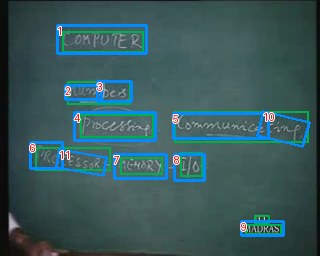

region,text,polygon,native_confidence,overlay
1,ConPuter,"[[57.0, 25.0], [146.0, 25.0], [146.0, 53.0], [57.0, 53.0]]",0.4301562108386589,drawn; geometry validity not inferred
2,MWl6,"[[65.0, 85.0], [101.0, 85.0], [101.0, 99.0], [65.0, 99.0]]",0.06425940245389938,drawn; geometry validity not inferred
3,~bes,"[[97.0, 81.0], [131.0, 81.0], [131.0, 101.0], [97.0, 101.0]]",0.13105419278144836,drawn; geometry validity not inferred
4,(prcrt,"[[74.0, 112.0], [155.0, 112.0], [155.0, 140.0], [74.0, 140.0]]",0.33073726643450807,drawn; geometry validity not inferred
5,ComuniceL,"[[173.0, 113.0], [268.0, 113.0], [268.0, 138.0], [173.0, 138.0]]",0.3655220172061761,drawn; geometry validity not inferred
6,Pko,"[[30.0, 142.0], [62.0, 142.0], [62.0, 168.0], [30.0, 168.0]]",0.5395445177266258,drawn; geometry validity not inferred
7,hcmery,"[[114.0, 154.0], [166.0, 154.0], [166.0, 178.0], [114.0, 178.0]]",0.1443104482598474,drawn; geometry validity not inferred
8,1o,"[[174.0, 154.0], [204.0, 154.0], [204.0, 180.0], [174.0, 180.0]]",0.20489588538152814,drawn; geometry validity not inferred
9,MADRiS,"[[241.0, 221.0], [283.0, 221.0], [283.0, 235.0], [241.0, 235.0]]",0.4568623232540811,drawn; geometry validity not inferred
10,cbf,"[[263.0513167019495, 111.15395010584845], [309.9067531318734, 122.25785026420255], [302.9486832980505, 146.84604989415155], [257.0932468681266, 135.74214973579745]]",0.11674625752598636,drawn; geometry validity not inferred


paddle_db_v3_rec_v4_t4 status= ok error= None regions= 7


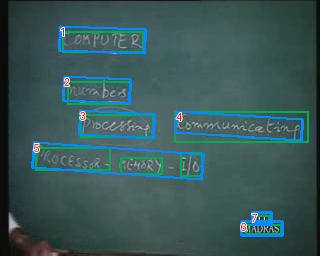

region,text,polygon,native_confidence,overlay
1,COMPUTER,"[[60.0, 26.0], [145.0, 29.0], [144.0, 53.0], [59.0, 50.0]]",0.8729833960533142,drawn; geometry validity not inferred
2,murnbes,"[[64.0, 76.0], [130.0, 79.0], [129.0, 103.0], [63.0, 100.0]]",0.802568256855011,drawn; geometry validity not inferred
3,proctiag,"[[80.0, 110.0], [154.0, 114.0], [153.0, 138.0], [79.0, 134.0]]",0.7386942505836487,drawn; geometry validity not inferred
4,Cormumicetinp,"[[176.0, 111.0], [302.0, 119.0], [301.0, 140.0], [175.0, 132.0]]",0.8957421779632568,drawn; geometry validity not inferred
5,PROCESSOR-MCHORy-iO,"[[34.0, 142.0], [203.0, 154.0], [201.0, 179.0], [32.0, 167.0]]",0.7607368230819702,drawn; geometry validity not inferred
6,MADRAS,"[[241.0, 221.0], [282.0, 221.0], [282.0, 235.0], [241.0, 235.0]]",0.9957945346832275,drawn; geometry validity not inferred
7,IIT,"[[252.0, 212.0], [271.0, 212.0], [271.0, 224.0], [252.0, 224.0]]",0.8683974146842957,drawn; geometry validity not inferred


tesseract5_best_eng_cpu status= ok error= None regions= 0


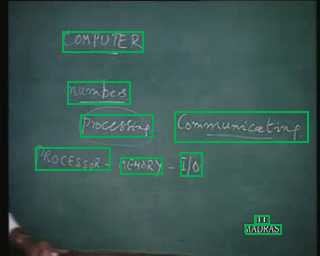

Zero rows; no entries omitted.
doctr_fast_base_parseq_t4 status= ok error= None regions= 12


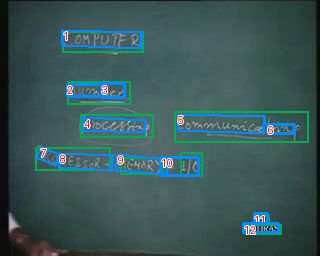

region,text,polygon,native_confidence,overlay
1,COMPUTER,"[[62.93402671813965, 30.059626579284668], [141.37734413146973, 32.82414722442627], [140.81597328186035, 48.75286865234375], [62.37265586853027, 45.98835277557373]]",0.993185818195343,drawn; geometry validity not inferred
2,TLUX,"[[67.1875, 84.24999046325684], [105.0, 84.24999046325684], [105.0, 96.74999046325684], [67.1875, 96.74999046325684]]",0.7210133075714111,drawn; geometry validity not inferred
3,bes,"[[101.87499046325684, 83.62499046325684], [124.68749046325684, 83.62499046325684], [124.68749046325684, 97.37499046325684], [101.87499046325684, 97.37499046325684]]",0.9793797731399536,drawn; geometry validity not inferred
4,Proceshin,"[[83.81521224975586, 117.56582069396973], [145.11917114257812, 120.0040512084961], [144.62230682373047, 132.4967269897461], [83.3183479309082, 130.05848693847656]]",0.9141180515289307,drawn; geometry validity not inferred
5,Communice,"[[178.48102569580078, 114.13656997680664], [264.1738510131836, 116.55531692504883], [263.7064743041992, 133.1134490966797], [178.0136489868164, 130.6947021484375]]",0.9960310459136963,drawn; geometry validity not inferred
6,an,"[[267.5, 124.25], [294.375, 124.25], [294.375, 133.625], [267.5, 133.625]]",0.6335240006446838,drawn; geometry validity not inferred
7,RO,"[[41.174564361572266, 147.09482955932617], [59.655160903930664, 154.48706436157227], [55.387916564941406, 165.15517044067383], [36.90731763839722, 157.76293563842773]]",0.9182410836219788,drawn; geometry validity not inferred
8,CESSOR-,"[[59.86053466796875, 153.14101028442383], [112.39173889160156, 155.65962600708008], [111.70196533203125, 170.04648971557617], [59.17076110839844, 167.52787399291992]]",0.9980471134185791,drawn; geometry validity not inferred
9,MENORY,"[[117.86238670349121, 154.2088394165039], [168.03356170654297, 159.00460052490234], [166.51260375976562, 174.91619873046875], [116.34142875671387, 170.1204376220703]]",0.8358873128890991,drawn; geometry validity not inferred
10,--40,"[[160.62498092651367, 157.06248092651367], [198.12498092651367, 157.06248092651367], [198.12498092651367, 175.49998092651367], [160.62498092651367, 175.49998092651367]]",0.8308303356170654,drawn; geometry validity not inferred


paddle_ppocrv6_medium_t4 status= ok error= None regions= 7


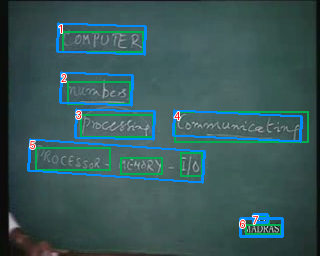

region,text,polygon,native_confidence,overlay
1,COMPUTER,"[[58.0, 23.0], [145.0, 26.0], [144.0, 54.0], [57.0, 51.0]]",0.9998623728752136,drawn; geometry validity not inferred
2,numbers,"[[61.0, 72.0], [132.0, 75.0], [131.0, 105.0], [60.0, 102.0]]",0.9985632300376892,drawn; geometry validity not inferred
3,Processing,"[[76.0, 109.0], [154.0, 111.0], [153.0, 139.0], [75.0, 137.0]]",0.8434067964553833,drawn; geometry validity not inferred
4,Communicating,"[[174.0, 110.0], [301.0, 116.0], [300.0, 141.0], [173.0, 135.0]]",0.9790679216384888,drawn; geometry validity not inferred
5,PROCESSOR-MEMORY-I/O,"[[30.0, 139.0], [204.0, 151.0], [202.0, 182.0], [28.0, 170.0]]",0.9869486093521118,drawn; geometry validity not inferred
6,MADRAS,"[[240.0, 218.0], [282.0, 218.0], [282.0, 236.0], [240.0, 236.0]]",0.9996044039726257,drawn; geometry validity not inferred
7,IT,"[[253.0, 214.0], [267.0, 214.0], [267.0, 222.0], [253.0, 222.0]]",0.8611814975738525,drawn; geometry validity not inferred


pgnet_totaltext_joint_t4 status= ok error= None regions= 8


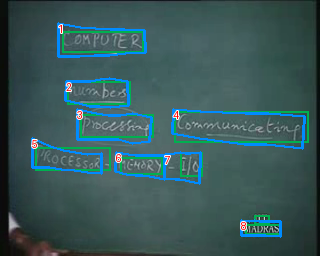

region,text,polygon,native_confidence,overlay
1,comruner,"[[58.0, 23.0], [80.0, 27.0], [95.0, 28.0], [110.0, 29.0], [124.0, 29.0], [144.0, 30.0], [145.0, 52.0], [125.0, 53.0], [109.0, 55.0], [94.0, 55.0], [79.0, 56.0], [58.0, 56.0]]",not supplied,drawn; geometry validity not inferred
2,muabes,"[[66.0, 81.0], [80.0, 81.0], [90.0, 81.0], [100.0, 79.0], [109.0, 78.0], [127.0, 81.0], [128.0, 105.0], [110.0, 107.0], [99.0, 106.0], [89.0, 106.0], [79.0, 103.0], [65.0, 100.0]]",not supplied,drawn; geometry validity not inferred
3,prcsihat,"[[77.0, 109.0], [96.0, 113.0], [108.0, 115.0], [120.0, 115.0], [132.0, 113.0], [151.0, 117.0], [149.0, 141.0], [132.0, 143.0], [118.0, 139.0], [106.0, 139.0], [93.0, 139.0], [77.0, 139.0]]",not supplied,drawn; geometry validity not inferred
4,commmumicelinf,"[[173.0, 109.0], [200.0, 111.0], [222.0, 112.0], [245.0, 113.0], [268.0, 113.0], [304.0, 116.0], [302.0, 148.0], [266.0, 144.0], [244.0, 144.0], [222.0, 141.0], [199.0, 138.0], [172.0, 133.0]]",not supplied,drawn; geometry validity not inferred
5,processor,"[[32.0, 138.0], [50.0, 146.0], [63.0, 150.0], [75.0, 152.0], [87.0, 154.0], [101.0, 153.0], [101.0, 173.0], [87.0, 172.0], [74.0, 170.0], [61.0, 169.0], [49.0, 167.0], [32.0, 167.0]]",not supplied,drawn; geometry validity not inferred
6,mekory,"[[116.0, 152.0], [128.0, 154.0], [135.0, 155.0], [142.0, 155.0], [150.0, 155.0], [164.0, 155.0], [164.0, 179.0], [149.0, 176.0], [142.0, 175.0], [135.0, 175.0], [126.0, 174.0], [115.0, 171.0]]",not supplied,drawn; geometry validity not inferred
7,ilo,"[[165.0, 154.0], [174.0, 153.0], [180.0, 152.0], [185.0, 153.0], [190.0, 153.0], [200.0, 152.0], [199.0, 183.0], [189.0, 181.0], [185.0, 180.0], [179.0, 179.0], [175.0, 179.0], [164.0, 178.0]]",not supplied,drawn; geometry validity not inferred
8,madras,"[[241.0, 220.0], [249.0, 221.0], [254.0, 220.0], [259.0, 221.0], [264.0, 221.0], [280.0, 221.0], [280.0, 236.0], [265.0, 235.0], [260.0, 235.0], [255.0, 235.0], [250.0, 235.0], [241.0, 235.0]]",not supplied,drawn; geometry validity not inferred


Viewer is descriptive: selective labels mean unmatched visible text may be unannotated; do not tune/filter test outputs.


In [15]:
from experiments.scripts.spotting_colab_frame_review import inspect_frame
selected_frame = FRAME_SELECTOR.value if FRAME_SELECTOR is not None else FRAME_ID
inspect_frame(OUT,ROOT,WORK,selected_frame)


In [16]:
# Optional download of any complete export listed in analysis artifacts.
EXPORT_FILE = 'all-prediction-text.csv.gz'
summary = read(OUT/'analysis-summary.json')
assert EXPORT_FILE in summary['artifacts']
assert file_sha(OUT/EXPORT_FILE)==summary['artifacts'][EXPORT_FILE]['sha256']
files.download(str(OUT/EXPORT_FILE))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Export evidence — kể cả khi thiếu test/analysis
Cell cuối chạy riêng sau lỗi để lưu partial evidence. ZIP trên Drive chứa logs, prepared/runtime seals, checkpoints, completion và kết quả đã tạo. ZIP không chứng minh completion; analysis/gates mới quyết định trạng thái. File→Save rồi Download.ipynb để giữ outputs. Cache/wheels nằm ngoài evidence ZIP và được giữ trên Drive để resume.


In [17]:
from experiments.scripts.spotting_colab_notebook import export_evidence
exported = export_evidence(OUT)
print(json.dumps(exported, indent=2))
files.download(exported['path'])


{
  "path": "/content/drive/MyDrive/OCR/cvid-spotting-t4-261015-v2-r5-evidence.zip",
  "sha256": "358a51fa96576cbb77820bcbe2177f1b7658556f0e7af1a0355a9276d7b38151",
  "files": 10648,
  "completed_comparison": true
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>